## Structural Properties


> **This is the most important module.** Understanding *what graph metrics measure* and *how to interpret them* separates a data scientist who uses graphs from one who truly understands them.

We will study every property in the same structured format:
1. Plain-English meaning
2. Why it matters
3. Mathematical definition (explained symbol by symbol)
4. NetworkX function
5. Small graph example
6. Python code + output
7. Interpretation of low, high, zero, and unusual values
8. What you can and cannot conclude
9. Practical application + exercise

---

### Structural Metric0: Number of Nodes and Edges

Already covered in Module 1. Quick recap:
- **Nodes (N):** Count of entities in your graph.
- **Edges (M or E):** Count of relationships.
- Together they set the scale of the graph — all other metrics must be interpreted relative to N and M.

### Structural Metric1:  Density

#### Plain-English Meaning

**Density** measures how many edges are present as a fraction of the **maximum possible** number of edges.

- **Density = 0.0**: no edges at all (empty graph).
- **Density = 1.0**:  every possible pair of nodes is connected (complete graph).
- **Density = 0.05**: only 5% of all possible connections are present.

#### Why It Matters

Density tells you how "full" a graph is. A social network of 1 billion people with 50 billion connections sounds dense, but its density is actually very low because the maximum possible connections would be ~500 quintillion.

#### Mathematical Definition

For an **undirected** simple graph:

$$\text{density} = \frac{2 \times M}{N \times (N - 1)}$$

Where:
- **M** = number of actual edges
- **N** = number of nodes
- **N × (N − 1) / 2** = maximum possible edges (every node paired with every other node, without repetition)

For a **directed** graph, the denominator becomes **N × (N − 1)** (because A→B and B→A are separate).

#### Interpretation
| Density | Interpretation |
|---------|----------------|
| ~0 | Very sparse: most nodes barely interact. We have 0 Edges |
| ~0.1 | Sparse: typical of social networks |
| ~0.5 | Moderately dense |
| ~1.0 | Dense or complete: everyone connected to everyone |

In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# DENSITY — comparing three graphs of the same size
# ─────────────────────────────────────────────────────────────────────────────

import networkx as nx
# Graph 1: Sparse — only a few edges
G_sparse = nx.path_graph(6)          # 6 nodes in a line: 0-1-2-3-4-5

# Graph 2: Medium — a cycle
G_medium = nx.cycle_graph(6)         # 6 nodes in a ring: 0-1-2-3-4-5-0

# Graph 3: Complete — every node connected to every other
G_complete = nx.complete_graph(6)    # 6 nodes, all 15 possible edges

graphs = [
    ("Path graph (6 nodes, 5 edges)",      G_sparse),
    ("Cycle graph (6 nodes, 6 edges)",     G_medium),
    ("Complete graph (6 nodes, 15 edges)", G_complete),
]

print("=" * 60)
print("GRAPH DENSITY COMPARISON")
print("=" * 60)
print(f"{'Graph':45s}  {'Nodes':5s}  {'Edges':5s}  {'Density':8s}")
print("-" * 70)

for name, g in graphs:
    n      = g.number_of_nodes()
    m      = g.number_of_edges()
    density = nx.density(g)
    print(f"{name:45s}  {n:5d}  {m:5d}  {density:.4f}")

# ─────────────────────────────────────────────────────────────────────────────
# Manual density calculation to verify NetworkX
# ─────────────────────────────────────────────────────────────────────────────
print("\nManual verification for path graph:")
n, m = 6, 5
manual = (2 * m) / (n * (n - 1))
print(f"  (2 × {m}) / ({n} × {n-1}) = {2*m} / {n*(n-1)} = {manual:.4f}")
print(f"  NetworkX result: {nx.density(G_sparse):.4f}")
print(f"  Match: {abs(manual - nx.density(G_sparse)) < 1e-10}")

GRAPH DENSITY COMPARISON
Graph                                          Nodes  Edges  Density 
----------------------------------------------------------------------
Path graph (6 nodes, 5 edges)                      6      5  0.3333
Cycle graph (6 nodes, 6 edges)                     6      6  0.4000
Complete graph (6 nodes, 15 edges)                 6     15  1.0000

Manual verification for path graph:
  (2 × 5) / (6 × 5) = 10 / 30 = 0.3333
  NetworkX result: 0.3333
  Match: True


## Structural Metric 2: Degree Distribution

#### Plain-English Meaning

Rather than looking at one node's degree, the **degree distribution** shows how degrees are spread across **all nodes** in the graph.

- In a **random** graph, most nodes have similar degrees (bell-curve distribution).
- In a **scale-free** network (like the internet or Twitter), a few nodes have extremely high degrees (hubs), while most have very low degrees. This is called a **power-law distribution**.

#### Why It Matters

The degree distribution reveals the graph's **structural type** and has major implications for:
- **Robustness:** Scale-free networks are resilient to random failures but vulnerable to targeted hub attacks.
- **Epidemic spread:** Hubs accelerate virus or information propagation dramatically.
- **Algorithm selection:** Highly skewed distributions require different analytical approaches.

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# DEGREE DISTRIBUTION — comparing random vs scale-free networks
# ─────────────────────────────────────────────────────────────────────────────
import collections

# Erdős–Rényi random graph: each pair of nodes is connected with probability p
# seed=42 makes results reproducible
G_random    = nx.erdos_renyi_graph(n=100, p=0.08, seed=42)

# Barabási–Albert scale-free graph: new nodes attach preferentially to high-degree nodes
# m=3 means each new node adds 3 edges
G_scalefree = nx.barabasi_albert_graph(n=100, m=3, seed=42)

def degree_stats(G, label):
    """Print degree statistics for a graph."""
    degrees = [d for _, d in G.degree()]
    print(f"\n{label}")
    print(f"  Min degree    : {min(degrees)}")
    print(f"  Max degree    : {max(degrees)}")
    print(f"  Average degree: {sum(degrees)/len(degrees):.2f}")
    # Count how many nodes have each degree value
    degree_count = collections.Counter(degrees)
    top_5 = sorted(degree_count.items(), key=lambda x: -x[0])[:5]
    print(f"  5 highest degrees seen: {top_5}")

print("=" * 60)
print("DEGREE STATISTICS: Random vs Scale-Free (100 nodes each)")
print("=" * 60)

degree_stats(G_random,    "Erdős–Rényi Random Graph")
degree_stats(G_scalefree, "Barabási–Albert Scale-Free Graph")



DEGREE STATISTICS: Random vs Scale-Free (100 nodes each)

Erdős–Rényi Random Graph
  Min degree    : 1
  Max degree    : 13
  Average degree: 7.42
  5 highest degrees seen: [(13, 3), (12, 4), (11, 3), (10, 7), (9, 17)]

Barabási–Albert Scale-Free Graph
  Min degree    : 3
  Max degree    : 30
  Average degree: 5.82
  5 highest degrees seen: [(30, 1), (28, 1), (26, 1), (23, 2), (19, 1)]


## Visualization

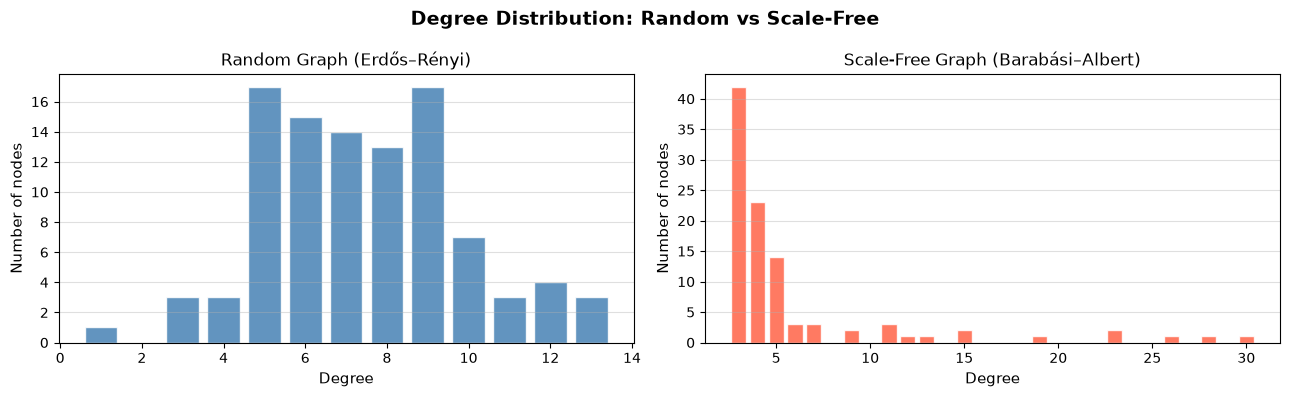


Interpretation:
  Random graph: degrees cluster around the average — bell-curve shape.
  Scale-free graph: most nodes have low degree, but a few HUBS have very high degree.
  The scale-free tail extends much further to the right.


In [3]:
import matplotlib.pyplot as plt
# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZE the degree distributions side by side
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, graph, title, color in [
    (axes[0], G_random,    "Random Graph (Erdős–Rényi)",    "steelblue"),
    (axes[1], G_scalefree, "Scale-Free Graph (Barabási–Albert)", "tomato"),
]:
    degrees = sorted([d for _, d in graph.degree()])
    counts  = collections.Counter(degrees)
    ax.bar(counts.keys(), counts.values(), color=color, edgecolor="white", alpha=0.85)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Degree", fontsize=11)
    ax.set_ylabel("Number of nodes", fontsize=11)
    ax.grid(axis="y", alpha=0.4)

plt.suptitle("Degree Distribution: Random vs Scale-Free", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("  Random graph: degrees cluster around the average — bell-curve shape.")
print("  Scale-free graph: most nodes have low degree, but a few HUBS have very high degree.")
print("  The scale-free tail extends much further to the right.")

##  Connectivity and Reachability Metrcis

###  Shortest Path Length, Diameter, Radius, Eccentricity

#### Definitions

| Term | Definition | Intuition |
|------|-----------|----------|
| **Shortest path** | Fewest edges between two nodes | The most direct route |
| **Eccentricity** of node v | Maximum shortest path from v to any other node | How "far" is the farthest node from v? |
| **Diameter** | Maximum eccentricity across all nodes | The longest shortest path in the graph |
| **Radius** | Minimum eccentricity across all nodes | The most centrally-located node's reach |
| **Average shortest path length** | Mean of all pairwise shortest path lengths | The typical number of hops between two random nodes |




### Eccentricity in a graph

- Eccentricity tells us how far a node is from the node that is farthest away from it, using the shortest paths between nodes.

- In simple words, it answers this question:What is the maximum number of steps I need to reach any other node from this node?

- It helps us understand how centrally or remotely a node is located in a network.

- For example, in a social network, a person with a low eccentricity can reach everyone else in relatively few steps. In a computer network, eccentricity can help identify how many connections or steps are needed to reach the farthest computer.

- Low eccentricity → the farthest node is relatively close.
- High eccentricity → the farthest node is relatively far away.

| Node | Farthest node(s) | Maximum shortest distance | Eccentricity |
|------|------------------|---------------------------|--------------|
| A    | E                | 4                         | 4            |
| B    | E                | 3                         | 3            |
| C    | A and E          | 2                         | 2            |
| D    | A                | 3                         | 3            |
| E    | A                | 4                         | 4            |

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CONNECTIVITY METRICS on our friendship graph
# ─────────────────────────────────────────────────────────────────────────────
# Use our 5-node friendship graph (a cycle: Alice-Bob-Carol-Eve-David-Alice)

import networkx as nx
G = nx.Graph()
G.add_edges_from([
    ("Alice", "Bob"),
    ("Bob",   "Carol"),
    ("Carol", "Eve"),
    ("Eve",   "David"),
    ("David", "Alice"),
])

print("=" * 60)
print("CONNECTIVITY METRICS — 5-Node Friendship Ring")
print("=" * 60)

# ── Eccentricity ─────────────────────────────────────────────────────────────
# eccentricity[v] = max shortest path from v to any other node
ecc = nx.eccentricity(G)
print("\nEccentricity of each node:")
for node, e in sorted(ecc.items()):
    print(f"  {node:8s} → eccentricity = {e}")



### Diameter of the Graph

- The diameter of a graph is the largest shortest-path distance between any two nodes in the graph.

- In simple language, it answers this question: What is the maximum number of steps needed to travel between two nodes, always taking the shortest possible path?

- Eccentricity	The maximum shortest-path distance from one specific node to any other node.

- Diameter	The maximum eccentricity across all nodes in the graph.

- Eccentricity focuses on one node; diameter describes the entire graph.

In [ ]:
# ── Diameter ─────────────────────────────────────────────────────────────────
diameter = nx.diameter(G)
print(f"\nDiameter (longest shortest path)     : {diameter}")
# The farthest apart two nodes are across the entire graph



### Radius of the Graph

- The radius of a graph is the smallest eccentricity among all nodes in the graph.

- In simple language, it answers this question: What is the smallest possible maximum distance from one node to all the other nodes?

- Eccentricity: The farthest distance from one specific node.

- Radius: The smallest eccentricity in the graph.

- Diameter: The largest eccentricity in the graph.

- Real-world example: Imagine a company choosing a location for a central delivery hub. A location with low eccentricity can reach all other locations within relatively few steps. The graph's radius tells us the minimum possible maximum distance from a node to all others.

In [ ]:
# ── Radius ───────────────────────────────────────────────────────────────────
radius = nx.radius(G)
print(f"Radius   (smallest eccentricity)     : {radius}")



### Average Shortest Path

- The average shortest path length is the average number of edges needed to travel between every pair of nodes in a graph, using the shortest possible path for each pair.

- In simple language, it answers this question: On average, how many steps does it take to get from one person to another in this network?

- Low Average Shortest Path: Nodes can reach each other in relatively few steps.

- High Average Shortest Path: Nodes are farther apart on average.

- Real-world example: In a social network, a low average shortest path length means people can connect to each other through only a few friendships. In a computer network, it can indicate that information can travel between computers in relatively few network links.

- Eccentricity: the farthest shortest-path distance from one node.

- Diameter: the largest eccentricity in the graph.

- Radius: the smallest eccentricity in the graph.

- Average shortest path length: the average shortest-path distance across all pairs of nodes.



In [12]:
# ── Average shortest path length ─────────────────────────────────────────────
avg_path = nx.average_shortest_path_length(G)
print(f"Average shortest path length         : {avg_path:.4f}")



Average shortest path length         : 1.5000


In [13]:
# ── Show all pairwise shortest path lengths manually ─────────────────────────
print("\nAll pairwise shortest path lengths:")
nodes = sorted(G.nodes())
print(f"  {'':8s}", end="")
for col in nodes:
    print(f"{col:8s}", end="")
print()

for row in nodes:
    print(f"  {row:8s}", end="")
    for col in nodes:
        length = nx.shortest_path_length(G, row, col)
        print(f"{length:8d}", end="")
    print()


All pairwise shortest path lengths:
          Alice   Bob     Carol   David   Eve     
  Alice          0       1       2       1       2
  Bob            1       0       1       2       2
  Carol          2       1       0       2       1
  David          1       2       2       0       1
  Eve            2       2       1       1       0


## Articulation Points and Bridges

#### Definitions

- **Articulation point** (also called a *cut vertex*): A node whose removal would **disconnect** the graph or split it into more components.
- **Bridge**: An edge whose removal would **disconnect** the graph.

#### Why They Matter

These are **vulnerabilities** in the network. In:
- A **road network**, a bridge edge is a road with no alternative route — if it closes, communities are isolated.
- An **organizational network**, an articulation point is an employee whose departure would break communication between teams.
- A **computer network**, articulation points are single points of failure.

In [14]:

T = nx.Graph()
T.add_edges_from([
    ("A",   "B"),
    ("B",   "C"),
    ("C",   "Hub"),   # Hub connects the two sides
    ("Hub", "D"),
    ("D",   "E"),
    ("E",   "F"),
])

print("=" * 55)
print("ARTICULATION POINTS AND BRIDGES")
print("=" * 55)

# Articulation points
art_points = list(nx.articulation_points(T))
print(f"Articulation points: {art_points}")
# → Every node in a path graph is an articulation point except the endpoints

# Bridges
bridges = list(nx.bridges(T))
print(f"Bridges            : {bridges}")
# → Every edge in a path graph is a bridge

print("\nVerification — remove 'Hub' and count components:")
T_no_hub = T.copy()
T_no_hub.remove_node("Hub")
comps = list(nx.connected_components(T_no_hub))
print(f"  Components after removing Hub: {len(comps)}")
for i, c in enumerate(comps, 1):
    print(f"    Component {i}: {sorted(c)}")



ARTICULATION POINTS AND BRIDGES
Articulation points: ['E', 'D', 'Hub', 'C', 'B']
Bridges            : [('A', 'B'), ('B', 'C'), ('C', 'Hub'), ('Hub', 'D'), ('D', 'E'), ('E', 'F')]

Verification — remove 'Hub' and count components:
  Components after removing Hub: 2
    Component 1: ['A', 'B', 'C']
    Component 2: ['D', 'E', 'F']


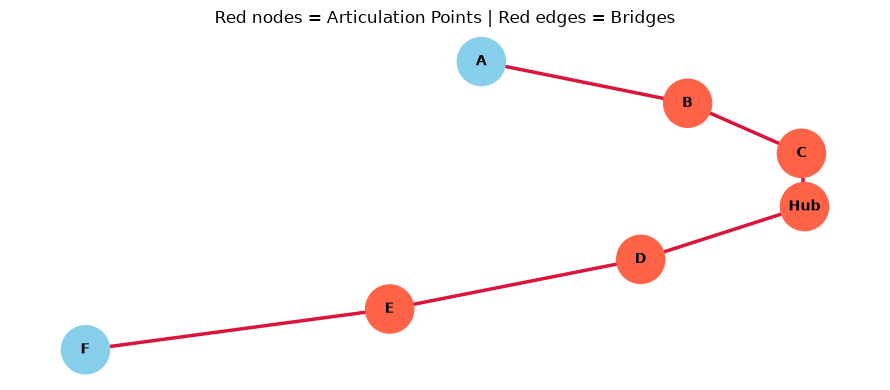

In [15]:
# ─────────────────────────────────────────────────────────────────────────────
# Visualize with articulation points highlighted in red
# ─────────────────────────────────────────────────────────────────────────────
plt.figure(figsize=(9, 4))
pos = nx.spring_layout(T, seed=5)

node_colors = ["tomato" if n in art_points else "skyblue" for n in T.nodes()]
edge_colors = ["crimson" if e in bridges or (e[1], e[0]) in bridges
               else "gray" for e in T.edges()]

nx.draw_networkx(
    T, pos,
    node_color=node_colors,
    edge_color=edge_colors,
    node_size=1200,
    font_size=10,
    font_weight="bold",
    width=2.5,
)

plt.title("Red nodes = Articulation Points | Red edges = Bridges", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()